# CIFAR-10 Linear Classification

**Understanding class scores, SVM hinge loss, and Softmax with random weights**

This notebook implements linear classifier computations directly in NumPy, following `Assignment Guideline.txt` and `Linear Classification.pptx`. The weights are initialized once and remain fixed throughout the notebook. No training is performed.

Tasks:

1. Select 10 CIFAR-10 test images, one from each class.
2. Compute class scores and predictions using small random weights and a zero bias vector.
3. Compute multiclass SVM hinge loss and the average loss over the selected examples.
4. Compare raw scores with Softmax probabilities and check that the probabilities sum to 1.
5. Show and explain correctly classified and misclassified examples.
6. Visualize the weight vector for each class as an RGB image.

## Running in Google Colab

1. Open this `.ipynb` file in Google Colab. A CPU runtime is sufficient.
2. Keep the default setting `DATA_SOURCE = "auto"` below and select **Runtime > Run all**.
3. When the upload dialog appears, select **both `test_batch` and `batches.meta`** from the provided `cifar-10-batches-py` folder. A ZIP containing both files also works.
4. If your data is in Google Drive, set `DATA_SOURCE = "drive"` and set `DRIVE_DATA_DIR` to the folder containing the two files.

The `auto` option first searches the current working directory. If it cannot find the data in Colab, it opens the upload dialog. After a runtime reset, upload the data again or reconnect Drive. To specify a local folder, use `DATA_SOURCE = "local"` and `LOCAL_DATA_DIR`.

Saved example outputs from a local run are included. Rerunning the notebook in Colab replaces them with outputs from that runtime.


## 1. Experiment settings

- **Weight seed 42**: makes the results reproducible when the same initialization code is rerun. The number 42 has no special mathematical meaning.
- **Normal distribution with mean 0 and standard deviation 0.01**: produces small random weights with a distribution symmetric around zero. The value 0.01 is an experimental choice, not a value specified by the assignment.
- **Example selection seed 2026**: uses a separate random generator so that selecting examples does not affect weight initialization.
- Input pixels are divided by `255` and represented as `float64` values in `[0, 1]`. Input and weight scales affect class scores, SVM loss, and Softmax probabilities, so these settings are documented together.

Adjust `DATA_SOURCE` and the paths below as needed. NumPy, pandas, and Matplotlib are available in a standard Colab runtime.


In [ ]:
from pathlib import Path, PurePosixPath
import io
import pickle
import tempfile
import zipfile

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

DATA_SOURCE = "auto"  # Choose "auto", "upload", "drive", or "local"
DRIVE_DATA_DIR = "/content/drive/MyDrive/cifar-10-batches-py"
LOCAL_DATA_DIR = ""  # Leave empty to search the current folder and its standard data subfolders

WEIGHT_SEED = 42
SAMPLE_SEED = 2026
WEIGHT_STD = 0.01
SVM_MARGIN = 1.0

np.set_printoptions(precision=6, suppress=True)
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 180)
get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print(f"NumPy {np.__version__} | pandas {pd.__version__} | Matplotlib {matplotlib.__version__}")
print(f"W seed={WEIGHT_SEED}, sample seed={SAMPLE_SEED}, W std={WEIGHT_STD}, margin={SVM_MARGIN}")


NumPy 2.2.5 | pandas 2.3.3 | Matplotlib 3.10.9
W seed=42, sample seed=2026, W std=0.01, margin=1.0


## 2. Connecting to and loading the data

This experiment uses `test_batch` and the class names in `batches.meta`. Since no training is performed, the training files `data_batch_1` through `data_batch_5` are not needed for these computations.

Use either direct upload or Google Drive. If you upload a ZIP, only the two required files are read from it. Use the CIFAR-10 batch files supplied with the assignment.


In [ ]:
REQUIRED_FILES = ("test_batch", "batches.meta")


def find_data_dir(base):
    '''Find both required files in the base folder or standard subfolders.'''
    base = Path(base).expanduser()
    candidates = [
        base,
        base / "cifar-10-batches-py",
        base / "data" / "cifar-10-batches-py",
        base / "data",
    ]
    return next(
        (folder for folder in candidates
         if all((folder / name).is_file() for name in REQUIRED_FILES)),
        None,
    )


def unpack_required_files(zip_payload, destination):
    '''Save only the two required ZIP members, regardless of their internal paths.'''
    destination = Path(destination)
    with zipfile.ZipFile(io.BytesIO(zip_payload)) as archive:
        for name in REQUIRED_FILES:
            matches = [
                info for info in archive.infolist()
                if not info.is_dir()
                and PurePosixPath(info.filename.replace("\\", "/")).name == name
            ]
            if len(matches) > 1:
                raise ValueError(f"The ZIP contains multiple copies of {name}. Include only one dataset folder.")
            if matches:
                (destination / name).write_bytes(archive.read(matches[0]))


def upload_data():
    if not IN_COLAB:
        raise RuntimeError("Run uploads in Colab. For local execution, use DATA_SOURCE='local'.")
    from google.colab import files

    upload_dir = Path(tempfile.mkdtemp(prefix="cifar10_", dir="/content"))
    print("Select both test_batch and batches.meta, or a ZIP containing both files.")
    uploaded = files.upload(target_dir=str(upload_dir))
    if not uploaded:
        raise ValueError("Upload canceled. Run this cell again.")
    for filename, payload in uploaded.items():
        if Path(filename).suffix.lower() == ".zip":
            unpack_required_files(payload, upload_dir)
    folder = find_data_dir(upload_dir)
    if folder is None:
        raise FileNotFoundError("Both test_batch and batches.meta are required. Rerun this cell and select both files.")
    return folder


if DATA_SOURCE not in {"auto", "upload", "drive", "local"}:
    raise ValueError("DATA_SOURCE must be auto, upload, drive, or local.")

data_dir = None
resolved_source = DATA_SOURCE
if DATA_SOURCE == "drive":
    if not IN_COLAB:
        raise RuntimeError("Connect to Drive from Colab.")
    from google.colab import drive

    drive.mount("/content/drive", readonly=True)
    data_dir = find_data_dir(DRIVE_DATA_DIR)
    if data_dir is None:
        raise FileNotFoundError("Check DRIVE_DATA_DIR and ensure it contains test_batch and batches.meta.")
elif DATA_SOURCE == "upload":
    data_dir = upload_data()
else:
    data_dir = find_data_dir(LOCAL_DATA_DIR or Path.cwd())
    if data_dir is None and LOCAL_DATA_DIR:
        raise FileNotFoundError("Check LOCAL_DATA_DIR and the two required data files.")
    if data_dir is None and IN_COLAB:
        data_dir = find_data_dir("/content")
    if data_dir is None and DATA_SOURCE == "auto" and IN_COLAB:
        data_dir = upload_data()
        resolved_source = "upload"
    elif data_dir is None:
        raise FileNotFoundError("Data not found. Set LOCAL_DATA_DIR or use the upload option in Colab.")
    else:
        resolved_source = "local"

print(f"Data connection ready: {resolved_source}, folder name: {data_dir.name}")


Data connection ready: local, folder name: cifar-10-batches-py


In [ ]:
def load_cifar_pickle(path):
    with Path(path).open("rb") as handle:
        return pickle.load(handle, encoding="latin1")


batch = load_cifar_pickle(data_dir / "test_batch")
meta = load_cifar_pickle(data_dir / "batches.meta")
raw_data = np.asarray(batch["data"])
y_all = np.asarray(batch["labels"], dtype=np.int64)
class_names = [
    name.decode("utf-8") if isinstance(name, bytes) else name
    for name in meta["label_names"]
]
NUM_CLASSES = len(class_names)
NUM_FEATURES = 3 * 32 * 32

assert NUM_CLASSES == 10
assert raw_data.shape == (len(y_all), NUM_FEATURES)
assert raw_data.dtype == np.uint8
assert np.all((0 <= y_all) & (y_all < NUM_CLASSES))
assert set(np.unique(y_all)) == set(range(NUM_CLASSES))

print(f"Test images: {len(y_all):,}")
print(f"Data shape: {raw_data.shape}, dtype: {raw_data.dtype}, pixel range: {raw_data.min()}~{raw_data.max()}")
display(pd.DataFrame({
    "class_id": np.arange(NUM_CLASSES),
    "class_name": class_names,
    "image_count": np.bincount(y_all, minlength=NUM_CLASSES),
}))


Test images: 10,000
Data shape: (10000, 3072), dtype: uint8, pixel range: 0~255


,class_id,class_name,image_count
0,0,airplane,1000
1,1,automobile,1000
2,2,bird,1000
3,3,cat,1000
4,4,deer,1000
5,5,dog,1000
6,6,frog,1000
7,7,horse,1000
8,8,ship,1000
9,9,truck,1000


## 3. Selecting examples and restoring RGB images

Select one image per class **before examining the predictions**. The average loss reported below is computed only over these 10 fixed examples.

Each CIFAR-10 row stores values in the order `[1024 R values][1024 G values][1024 B values]`. Therefore:

```text
3072 values -> (3, 32, 32): channel, height, width
            -> (32, 32, 3): height, width, channel
```

To display an image, use `reshape(3, 32, 32).transpose(1, 2, 0)`. Using only `reshape(32, 32, 3)` would group the RGB values incorrectly. Score computations use the original 3072-dimensional vector in its original channel order.


,example,test_index,true_class
0,1,8563,airplane
1,2,1769,automobile
2,3,291,bird
3,4,6364,cat
4,5,3621,deer
5,6,4844,dog
6,7,672,frog
7,8,3802,horse
8,9,6602,ship
9,10,3464,truck


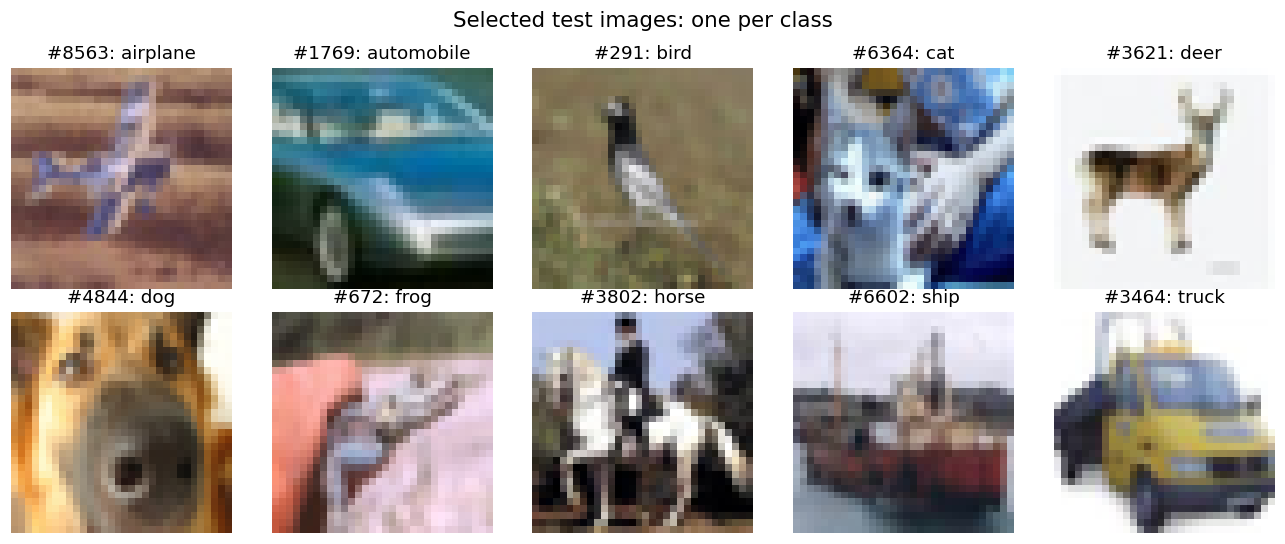

In [ ]:
sample_rng = np.random.default_rng(SAMPLE_SEED)
selected_indices = np.array([
    sample_rng.choice(np.flatnonzero(y_all == class_id))
    for class_id in range(NUM_CLASSES)
], dtype=np.int64)

X = raw_data[selected_indices].astype(np.float64) / 255.0
y = y_all[selected_indices]
images = raw_data[selected_indices].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)

assert X.shape == (10, 3072)
assert images.shape == (10, 32, 32, 3)
assert np.array_equal(images.transpose(0, 3, 1, 2).reshape(10, -1), raw_data[selected_indices])

display(pd.DataFrame({
    "example": np.arange(1, len(y) + 1),
    "test_index": selected_indices,
    "true_class": [class_names[label] for label in y],
}))

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i], interpolation="nearest")
    ax.set_title(f"#{selected_indices[i]}: {class_names[y[i]]}")
    ax.axis("off")
fig.suptitle("Selected test images: one per class", fontsize=14)
fig.tight_layout()
plt.show()


## 4. Random weights and linear scores

For a single image:

$$
x\in\mathbb{R}^{3072},\quad W\in\mathbb{R}^{10\times3072},\quad
b\in\mathbb{R}^{10},\qquad s=Wx+b
$$

The code stacks images as rows with `X.shape = (N, 3072)`, so batch scores are computed as `scores = X @ W.T + b`. The class with the highest score in each row is the prediction. Raw scores can be negative and are not probabilities.


In [ ]:
def initialize_parameters(seed, std, num_classes=10, num_features=3072):
    rng = np.random.default_rng(seed)
    weights = rng.normal(loc=0.0, scale=std, size=(num_classes, num_features))
    bias = np.zeros(num_classes, dtype=np.float64)
    return weights, bias


def linear_scores(inputs, weights, bias):
    '''Compute f(x)=Wx+b for a batch with one image per row.'''
    return inputs @ weights.T + bias


W, b = initialize_parameters(WEIGHT_SEED, WEIGHT_STD, NUM_CLASSES, NUM_FEATURES)
W_initial, b_initial = W.copy(), b.copy()
scores = linear_scores(X, W, b)
predictions = np.argmax(scores, axis=1)

assert W.shape == (10, 3072) and b.shape == (10,)
assert scores.shape == (len(X), 10)
np.testing.assert_allclose(scores[0], W @ X[0] + b, atol=1e-12, rtol=0)

print(f"W shape={W.shape}, b shape={b.shape}, scores shape={scores.shape}")
print(f"Generated W: sample mean={W.mean():.6f}, sample standard deviation={W.std():.6f}")
print("With a finite random sample, the sample mean and standard deviation may differ slightly from the distribution parameters.")

score_table = pd.DataFrame(scores, columns=class_names,
                           index=pd.Index(selected_indices, name="test_index"))
print("Raw scores for all 10 classes for each image:")
display(score_table.round(6))

prediction_table = pd.DataFrame({
    "test_index": selected_indices,
    "true_class": [class_names[label] for label in y],
    "predicted_class": [class_names[label] for label in predictions],
    "true_class_score": scores[np.arange(len(y)), y],
    "highest_score": scores[np.arange(len(y)), predictions],
    "correct": predictions == y,
})
display(prediction_table.round(6))


W shape=(10, 3072), b shape=(10,), scores shape=(10, 10)
Generated W: sample mean=0.000091, sample standard deviation=0.010044
With a finite random sample, the sample mean and standard deviation may differ slightly from the distribution parameters.
Raw scores for all 10 classes for each image:


,airplane,automobile,bird,cat,deer,dog,frog,horse,ship,truck
test_index,,,,,,,,,,
8563,-0.228801,0.059279,-0.018362,-0.516993,0.117530,0.551145,0.615772,0.331822,0.591689,-0.251242
1769,-0.171855,0.016812,-0.002421,-0.374271,0.200176,0.415052,0.410061,0.216878,0.604078,-0.064594
291,-0.423956,0.100340,-0.051245,-0.499497,0.069371,0.531481,0.611903,0.354982,0.460837,-0.215202
6364,-0.383211,0.306324,-0.223429,-0.486847,-0.053554,0.673899,0.779779,0.454528,0.617293,-0.264773
3621,-0.724597,-0.018499,0.185405,-0.855159,0.030474,1.153082,0.906926,0.830445,1.084761,-0.507388
4844,-0.363393,0.202502,-0.123038,-0.515729,0.144099,0.797709,0.811786,0.455541,0.401193,-0.195196
672,-0.508912,-0.085371,-0.040456,-0.389800,0.033874,0.670210,0.970371,0.367694,0.826725,-0.076778
3802,-0.183321,0.420552,0.127815,-0.704051,0.359475,0.414030,0.529117,0.241777,0.494542,-0.485277
6602,-0.187571,0.079045,0.007291,-0.775801,0.180744,0.592007,0.565221,0.551499,0.679385,-0.481343


,test_index,true_class,predicted_class,true_class_score,highest_score,correct
0,8563,airplane,frog,-0.228801,0.615772,False
1,1769,automobile,ship,0.016812,0.604078,False
2,291,bird,frog,-0.051245,0.611903,False
3,6364,cat,frog,-0.486847,0.779779,False
4,3621,deer,dog,0.030474,1.153082,False
5,4844,dog,frog,0.797709,0.811786,False
6,672,frog,frog,0.970371,0.970371,True
7,3802,horse,frog,0.241777,0.529117,False
8,6602,ship,ship,0.679385,0.679385,True
9,3464,truck,dog,-0.410537,0.616280,False


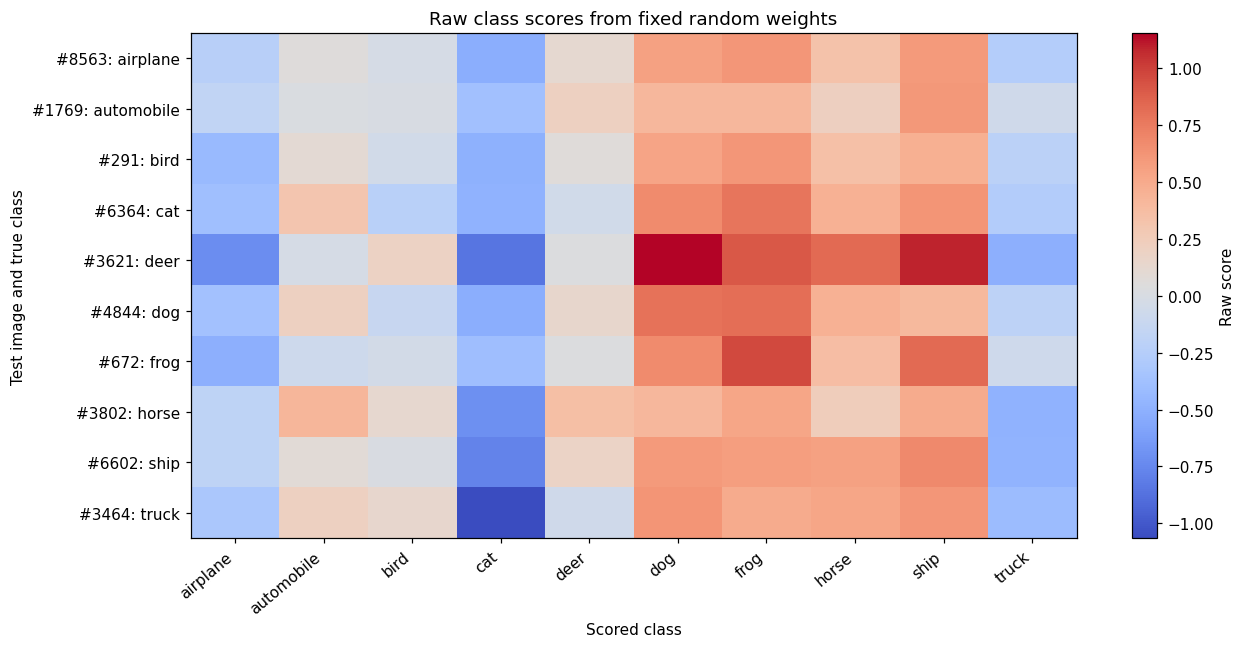

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))
heatmap = ax.imshow(scores, cmap="coolwarm", aspect="auto")
ax.set_xticks(np.arange(NUM_CLASSES), labels=class_names, rotation=40, ha="right")
ax.set_yticks(np.arange(len(y)), labels=[f"#{idx}: {class_names[label]}" for idx, label in zip(selected_indices, y)])
ax.set_xlabel("Scored class")
ax.set_ylabel("Test image and true class")
ax.set_title("Raw class scores from fixed random weights")
fig.colorbar(heatmap, ax=ax, label="Raw score")
fig.tight_layout()
plt.show()


## 5. Multiclass SVM hinge loss

Use the lecture's margin $\Delta=1$.

$$
L_i=\sum_{j\ne y_i}\max(0, s_{ij}-s_{i,y_i}+\Delta),\qquad
L=\frac{1}{N}\sum_{i=1}^{N}L_i
$$

Exclude the true class from the sum. A wrong class contributes to the loss if its score exceeds the true-class score, or if its score is lower but the difference is smaller than the margin. A correctly classified image can therefore still have positive loss. This notebook computes only the data loss, without adding a regularization term.


In [ ]:
def multiclass_svm_loss(class_scores, true_labels, delta=1.0):
    '''Return per-example losses, mean loss, and per-class hinge terms.'''
    rows = np.arange(len(true_labels))
    true_scores = class_scores[rows, true_labels][:, None]
    margins = np.maximum(0.0, class_scores - true_scores + delta)
    margins[rows, true_labels] = 0.0  # Exclude the true class
    per_example_loss = margins.sum(axis=1)
    return per_example_loss, float(per_example_loss.mean()), margins


losses, mean_loss, hinge_terms = multiclass_svm_loss(scores, y, SVM_MARGIN)
loss_table = prediction_table[["test_index", "true_class", "predicted_class", "correct"]].copy()
loss_table["svm_hinge_loss"] = losses
display(loss_table.round(6))
print(f"Average SVM hinge loss over the {len(y)} fixed main examples = {mean_loss:.6f}")


Average SVM hinge loss over the 10 fixed main examples = 8.993561


,test_index,true_class,predicted_class,correct,svm_hinge_loss
0,8563,airplane,frog,False,12.539851
1,1769,automobile,ship,False,10.081794
2,291,bird,frog,False,10.451466
3,6364,cat,frog,False,15.288479
4,3621,deer,dog,False,10.780708
5,4844,dog,frog,False,3.112928
6,672,frog,frog,True,2.017020
7,3802,horse,frog,False,7.796890
8,6602,ship,ship,True,4.032541
9,3464,truck,dog,False,13.833939


In [ ]:
# Break down the first misclassified example, or the first example if all predictions are correct.
wrong_positions = np.flatnonzero(predictions != y)
detail_pos = int(wrong_positions[0]) if len(wrong_positions) else 0
true_id = int(y[detail_pos])
wrong_ids = np.array([j for j in range(NUM_CLASSES) if j != true_id])
detail_table = pd.DataFrame({
    "wrong_class": [class_names[j] for j in wrong_ids],
    "score_j": scores[detail_pos, wrong_ids],
    "true_score": scores[detail_pos, true_id],
    "score_j - true_score + 1": scores[detail_pos, wrong_ids] - scores[detail_pos, true_id] + SVM_MARGIN,
    "hinge_contribution": hinge_terms[detail_pos, wrong_ids],
})
print(f"Loss breakdown: test_index={selected_indices[detail_pos]}, true class={class_names[true_id]}")
display(detail_table.round(6))
print(f"Sum of the last column = {detail_table['hinge_contribution'].sum():.6f}")
print(f"SVM loss for this example = {losses[detail_pos]:.6f}")


Loss breakdown: test_index=8563, true class=airplane
Sum of the last column = 12.539851
SVM loss for this example = 12.539851


,wrong_class,score_j,true_score,score_j - true_score + 1,hinge_contribution
0,automobile,0.059279,-0.228801,1.288080,1.288080
1,bird,-0.018362,-0.228801,1.210439,1.210439
2,cat,-0.516993,-0.228801,0.711808,0.711808
3,deer,0.117530,-0.228801,1.346331,1.346331
4,dog,0.551145,-0.228801,1.779946,1.779946
5,frog,0.615772,-0.228801,1.844574,1.844574
6,horse,0.331822,-0.228801,1.560623,1.560623
7,ship,0.591689,-0.228801,1.820491,1.820491
8,truck,-0.251242,-0.228801,0.977559,0.977559


## 6. Softmax: converting raw scores into probabilities

$$
p_{ij}=\frac{e^{s_{ij}-m_i}}{\sum_k e^{s_{ik}-m_i}},\qquad m_i=\max_k s_{ik}
$$

Subtracting the maximum score in each row prevents overflow in the exponential calculation while preserving the original Softmax probabilities. The probabilities are nonnegative and sum to 1 in each row. Softmax preserves score ordering, so the class with the highest probability is also the class with the highest raw score.

This model is untrained. Probabilities summing to 1 does not by itself mean that they accurately represent the likelihood of a correct prediction.


In [ ]:
def softmax(class_scores):
    shifted = class_scores - np.max(class_scores, axis=1, keepdims=True)
    exp_scores = np.exp(shifted)
    return exp_scores / np.sum(exp_scores, axis=1, keepdims=True)


probabilities = softmax(scores)
probability_sums = probabilities.sum(axis=1)
softmax_predictions = np.argmax(probabilities, axis=1)

np.testing.assert_allclose(probability_sums, np.ones(len(y)), atol=1e-12, rtol=0)
assert np.all(probabilities >= 0.0) and np.all(probabilities <= 1.0)
assert np.array_equal(predictions, softmax_predictions)

display(pd.DataFrame({
    "test_index": selected_indices,
    "probability_sum": probability_sums,
    "highest_probability_class": [class_names[j] for j in softmax_predictions],
    "same_prediction_as_raw_score": predictions == softmax_predictions,
}).round(12))
print(f"Maximum absolute difference between a probability sum and 1: {np.max(np.abs(probability_sums - 1)):.3e}")


Maximum absolute difference between a probability sum and 1: 1.110e-16


,test_index,probability_sum,highest_probability_class,same_prediction_as_raw_score
0,8563,1.0,frog,True
1,1769,1.0,ship,True
2,291,1.0,frog,True
3,6364,1.0,frog,True
4,3621,1.0,dog,True
5,4844,1.0,frog,True
6,672,1.0,frog,True
7,3802,1.0,frog,True
8,6602,1.0,ship,True
9,3464,1.0,dog,True


In [ ]:
# Show raw scores and probabilities for all 10 classes for every selected image.
for i, test_index in enumerate(selected_indices):
    display(Markdown(
        f"**test_index={test_index} · True class: {class_names[y[i]]} · Prediction: {class_names[predictions[i]]}**"
    ))
    comparison = pd.DataFrame({
        "class": class_names,
        "raw_score": scores[i],
        "softmax_probability": probabilities[i],
        "is_true_class": np.arange(NUM_CLASSES) == y[i],
        "is_predicted_class": np.arange(NUM_CLASSES) == predictions[i],
    })
    display(comparison.round(6))


**test_index=8563 · True class: airplane · Prediction: frog**

,class,raw_score,softmax_probability,is_true_class,is_predicted_class
0,airplane,-0.228801,0.065612,True,False
1,automobile,0.059279,0.087518,False,False
2,bird,-0.018362,0.080980,False,False
3,cat,-0.516993,0.049184,False,False
4,deer,0.117530,0.092767,False,False
5,dog,0.551145,0.143123,False,False
6,frog,0.615772,0.152678,False,True
7,horse,0.331822,0.114937,False,False
8,ship,0.591689,0.149045,False,False
9,truck,-0.251242,0.064156,False,False


**test_index=1769 · True class: automobile · Prediction: ship**

,class,raw_score,softmax_probability,is_true_class,is_predicted_class
0,airplane,-0.171855,0.071385,False,False
1,automobile,0.016812,0.086207,True,False
2,bird,-0.002421,0.084565,False,False
3,cat,-0.374271,0.058304,False,False
4,deer,0.200176,0.103557,False,False
5,dog,0.415052,0.128380,False,False
6,frog,0.410061,0.127741,False,False
7,horse,0.216878,0.105301,False,False
8,ship,0.604078,0.155092,False,True
9,truck,-0.064594,0.079468,False,False


**test_index=291 · True class: bird · Prediction: frog**

,class,raw_score,softmax_probability,is_true_class,is_predicted_class
0,airplane,-0.423956,0.055688,False,False
1,automobile,0.100340,0.094073,False,False
2,bird,-0.051245,0.080841,True,False
3,cat,-0.499497,0.051637,False,False
4,deer,0.069371,0.091204,False,False
5,dog,0.531481,0.144779,False,False
6,frog,0.611903,0.156904,False,True
7,horse,0.354982,0.121354,False,False
8,ship,0.460837,0.134904,False,False
9,truck,-0.215202,0.068616,False,False


... (10 outputs left out)

**test_index=6602 · True class: ship · Prediction: ship**

,class,raw_score,softmax_probability,is_true_class,is_predicted_class
0,airplane,-0.187571,0.066472,False,False
1,automobile,0.079045,0.086782,False,False
2,bird,0.007291,0.080773,False,False
3,cat,-0.775801,0.036913,False,False
4,deer,0.180744,0.096072,False,False
5,dog,0.592007,0.144946,False,False
6,frog,0.565221,0.141115,False,False
7,horse,0.551499,0.139192,False,False
8,ship,0.679385,0.158181,True,True
9,truck,-0.481343,0.049552,False,False


**test_index=3464 · True class: truck · Prediction: dog**

,class,raw_score,softmax_probability,is_true_class,is_predicted_class
0,airplane,-0.318288,0.060282,False,False
1,automobile,0.208407,0.102077,False,False
2,bird,0.137139,0.095055,False,False
3,cat,-1.065020,0.028568,False,False
4,deer,-0.064035,0.077733,False,False
5,dog,0.616280,0.153484,False,True
6,frog,0.489897,0.135262,False,False
7,horse,0.525503,0.140165,False,False
8,ship,0.609224,0.152405,False,False
9,truck,-0.410537,0.054970,True,False


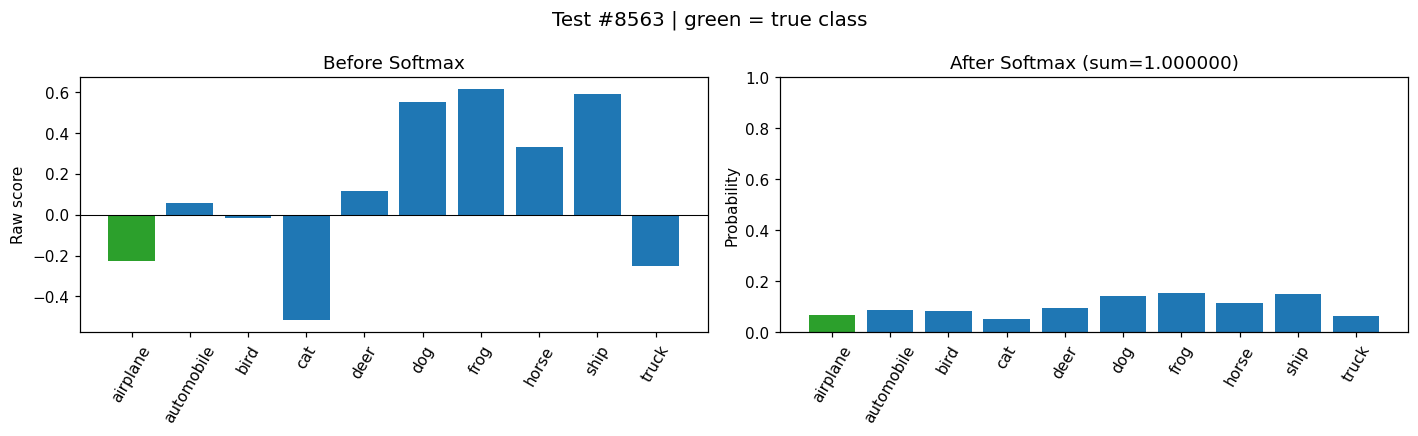

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
colors = ["tab:green" if j == y[detail_pos] else "tab:blue" for j in range(NUM_CLASSES)]
axes[0].bar(class_names, scores[detail_pos], color=colors)
axes[0].axhline(0, color="black", linewidth=0.7)
axes[0].set_ylabel("Raw score")
axes[0].set_title("Before Softmax")
axes[1].bar(class_names, probabilities[detail_pos], color=colors)
axes[1].set_ylabel("Probability")
axes[1].set_ylim(0, 1)
axes[1].set_title(f"After Softmax (sum={probability_sums[detail_pos]:.6f})")
for ax in axes:
    ax.tick_params(axis="x", labelrotation=60)
fig.suptitle(f"Test #{selected_indices[detail_pos]} | green = true class", fontsize=13)
fig.tight_layout()
plt.show()


## 7. Correctly classified and misclassified examples

Show up to 2 correctly classified and 2 misclassified images from the 10 main examples. If either type is absent, search the test set in index order **using the same weights** and add the first matching example. If no such example exists in the test set, report that it was not found.

Supplementary examples are used for explanation and are excluded from the previously reported average loss over the 10 main examples. The seed and weights are not changed to obtain correct predictions.


The average SVM loss over the original 10 examples remains 8.993561.


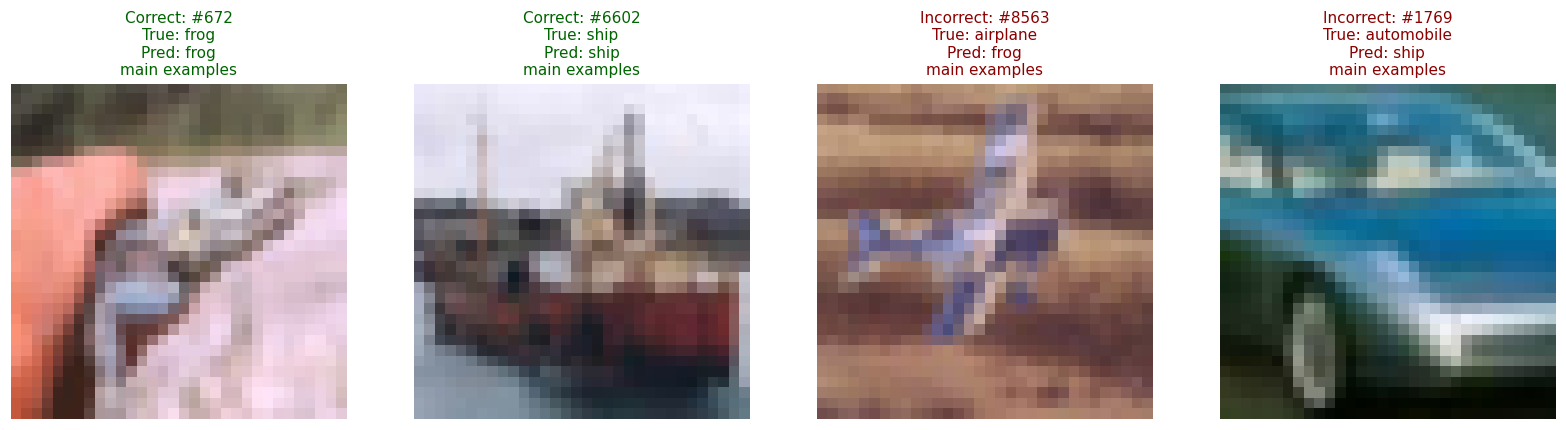

,test_index,source,true_class,predicted_class,true_class_score,highest_score,highest_probability,svm_hinge_loss
0,672,main examples,frog,frog,0.970371,0.970371,0.196331,2.017020
1,6602,main examples,ship,ship,0.679385,0.679385,0.158181,4.032541
2,8563,main examples,airplane,frog,-0.228801,0.615772,0.152678,12.539851
3,1769,main examples,automobile,ship,0.016812,0.604078,0.155092,10.081794


**Example #672:** The true class has the highest score, so the prediction is correct. The random weights happened to assign the highest score to the true class. However, the score gap does not reach the margin of 1 for every wrong class, so the SVM loss is positive.

**Example #6602:** The true class has the highest score, so the prediction is correct. The random weights happened to assign the highest score to the true class. However, the score gap does not reach the margin of 1 for every wrong class, so the SVM loss is positive.

**Example #8563:** The true class, airplane, was outscored by frog, so the prediction is incorrect. The weights have not been trained to align class scores with image content.

**Example #1769:** The true class, automobile, was outscored by ship, so the prediction is incorrect. The weights have not been trained to align class scores with image content.

In [ ]:
def find_first_case(want_correct, chunk_size=512):
    for start in range(0, len(y_all), chunk_size):
        stop = min(start + chunk_size, len(y_all))
        chunk = raw_data[start:stop].astype(np.float64) / 255.0
        chunk_predictions = linear_scores(chunk, W, b).argmax(axis=1)
        matches = np.flatnonzero((chunk_predictions == y_all[start:stop]) == want_correct)
        if len(matches):
            return start + int(matches[0])
    return None


case_specs = []
for want_correct, title in [(True, "Correct"), (False, "Incorrect")]:
    positions = np.flatnonzero((predictions == y) == want_correct)[:2]
    if len(positions):
        case_specs.extend((int(selected_indices[pos]), title, "main examples") for pos in positions)
    else:
        additional_index = find_first_case(want_correct)
        if additional_index is None:
            print(f"No {title} example was found in the test set.")
        else:
            case_specs.append((additional_index, title, "supplementary search"))

case_indices = np.array([spec[0] for spec in case_specs], dtype=np.int64)
case_X = raw_data[case_indices].astype(np.float64) / 255.0
case_y = y_all[case_indices]
case_scores = linear_scores(case_X, W, b)
case_pred = case_scores.argmax(axis=1)
case_probs = softmax(case_scores)
case_losses, _, _ = multiclass_svm_loss(case_scores, case_y, SVM_MARGIN)
case_images = raw_data[case_indices].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)

fig, axes = plt.subplots(1, len(case_specs), figsize=(3.7 * len(case_specs), 3.8), squeeze=False)
for i, ax in enumerate(axes.flat):
    test_index, title, origin = case_specs[i]
    ax.imshow(case_images[i], interpolation="nearest")
    ax.set_title(
        f"{title}: #{test_index}\nTrue: {class_names[case_y[i]]}\nPred: {class_names[case_pred[i]]}\n{origin}",
        color="darkgreen" if title == "Correct" else "darkred", fontsize=10,
    )
    ax.axis("off")
fig.tight_layout()
plt.show()

display(pd.DataFrame({
    "test_index": case_indices,
    "source": [spec[2] for spec in case_specs],
    "true_class": [class_names[j] for j in case_y],
    "predicted_class": [class_names[j] for j in case_pred],
    "true_class_score": case_scores[np.arange(len(case_y)), case_y],
    "highest_score": case_scores[np.arange(len(case_y)), case_pred],
    "highest_probability": case_probs[np.arange(len(case_y)), case_pred],
    "svm_hinge_loss": case_losses,
}).round(6))

for i, (test_index, title, origin) in enumerate(case_specs):
    if case_pred[i] == case_y[i]:
        explanation = "The true class has the highest score, so the prediction is correct. The random weights happened to assign the highest score to the true class."
        if case_losses[i] > 1e-12:
            explanation += " However, the score gap does not reach the margin of 1 for every wrong class, so the SVM loss is positive."
    else:
        explanation = (
            f"The true class, {class_names[case_y[i]]}, was outscored by {class_names[case_pred[i]]}, so the prediction is incorrect. "
            "The weights have not been trained to align class scores with image content."
        )
    display(Markdown(f"**Example #{test_index}:** {explanation}"))

print(f"The average SVM loss over the original 10 examples remains {mean_loss:.6f}.")


## 8. Visualizing the weights for each class

Each row of $W$ contains 3072 weights contributing to the score for one class. Restore the same RGB channel order used for the input images.

$$
(10,3072)\longrightarrow(10,3,32,32)\longrightarrow(10,32,32,3)
$$

Apply **the same display scale to every class** so that negative weights can also be visualized. If $a$ is the maximum absolute value across all weights, the display value is $(W/a+1)/2$. This transformation is used only for visualization and does not change the $W$ used for score computations. A pixel whose three channel weights are all zero appears as middle gray.


Shared weight display range across all classes: [-0.043891, 0.043891]


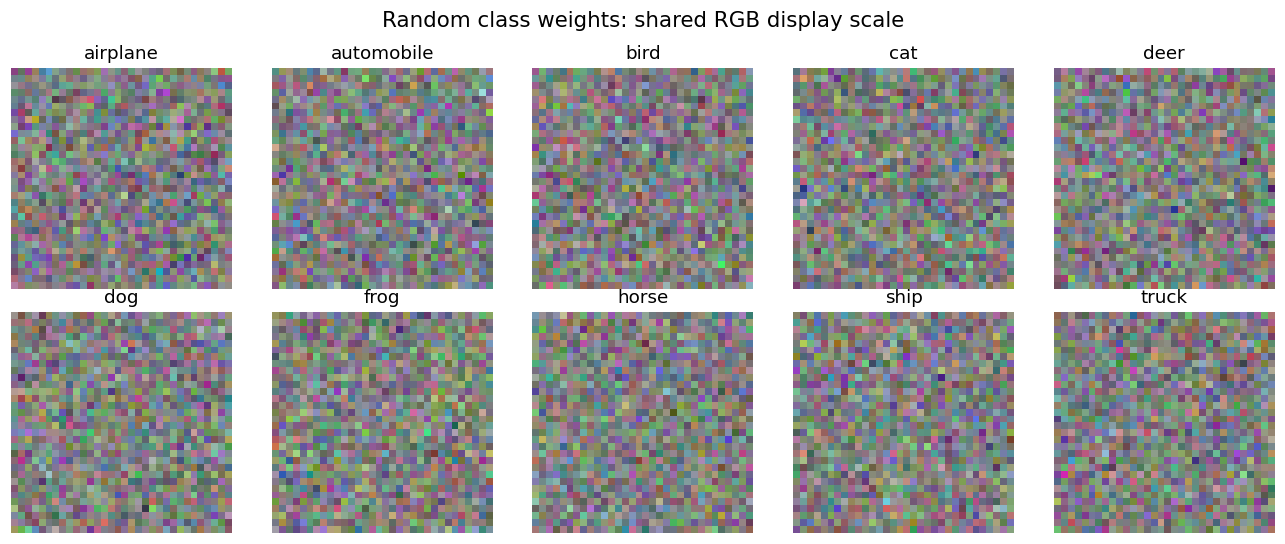

In [ ]:
weight_images = W.reshape(NUM_CLASSES, 3, 32, 32).transpose(0, 2, 3, 1)
max_abs_weight = float(np.abs(W).max())
weight_display = np.clip(0.5 + weight_images / (2.0 * max_abs_weight), 0.0, 1.0)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for class_id, ax in enumerate(axes.flat):
    ax.imshow(weight_display[class_id], interpolation="nearest")
    ax.set_title(class_names[class_id])
    ax.axis("off")
fig.suptitle("Random class weights: shared RGB display scale", fontsize=14)
fig.tight_layout()
plt.show()

print(f"Shared weight display range across all classes: [{-max_abs_weight:.6f}, {max_abs_weight:.6f}]")
assert np.array_equal(W, W_initial)


**Interpretation:** The class weights were generated independently from the same normal distribution. They have never been updated using the true labels, so meaningful class patterns, such as airplane outlines, car shapes, or frog colors, are not expected. The random color patterns reflect initialization.

The trained weight visualizations on slides 15-16 of the lecture illustrate class-related input patterns learned through training. The weights in this assignment remain at initialization, so the absence of such patterns is expected.


## 9. Results summary

The summary below is generated from the current execution results. If the experiment settings are changed and all cells are rerun, it updates accordingly.


In [ ]:
display(Markdown(f'''
- **Settings:** weight seed `{WEIGHT_SEED}`, example seed `{SAMPLE_SEED}`, normal weight distribution with mean `0` and standard deviation `{WEIGHT_STD}`, $b=0$, input pixels `/255`, and SVM margin `{SVM_MARGIN}`.
- **Scores and predictions:** computed 10 class scores for each of the `{len(y)}` main images, one per class, and selected the class with the highest score as the prediction.
- **Average SVM hinge loss:** **`{mean_loss:.6f}`** over the main examples. For each image, the margin violations between the true-class score and wrong-class scores were summed, then the losses were averaged.
- **Softmax:** the probabilities sum to 1 for every main example. The maximum absolute difference from 1 is `{np.max(np.abs(probability_sums - 1)):.3e}`. The class with the highest probability matches the class with the highest raw score.
- **Example interpretation:** correct predictions occur when the random scores happen to favor the true class. Misclassifications show that untrained weights do not guarantee scores consistent with image content. Supplementary examples are excluded from the main average loss.
- **Weight images:** all 10 classes show random patterns before training. No updates using images and labels were performed, so no meaningful class-specific patterns were learned.

The weights remained fixed throughout the notebook. Following the assignment guideline, accuracy, precision, recall, and F1 score were not computed.
'''))


- **Settings:** weight seed `42`, example seed `2026`, normal weight distribution with mean `0` and standard deviation `0.01`, $b=0$, input pixels `/255`, and SVM margin `1.0`.
- **Scores and predictions:** computed 10 class scores for each of the `10` main images, one per class, and selected the class with the highest score as the prediction.
- **Average SVM hinge loss:** **`8.993561`** over the main examples. For each image, the margin violations between the true-class score and wrong-class scores were summed, then the losses were averaged.
- **Softmax:** the probabilities sum to 1 for every main example. The maximum absolute difference from 1 is `1.110e-16`. The class with the highest probability matches the class with the highest raw score.
- **Example interpretation:** correct predictions occur when the random scores happen to favor the true class. Misclassifications show that untrained weights do not guarantee scores consistent with image content. Supplementary examples are excluded from the main average loss.
- **Weight images:** all 10 classes show random patterns before training. No updates using images and labels were performed, so no meaningful class-specific patterns were learned.

The weights remained fixed throughout the notebook. Following the assignment guideline, accuracy, precision, recall, and F1 score were not computed.


## References

- Provided `Assignment Guideline.txt`: assignment requirements
- Provided `Linear Classification.pptx`: slides 12-13 for linear scores and dimensions, 15-16 for weight interpretation, 22-26 for SVM hinge loss, and 27-29 for Softmax
- Provided `cifar-10-batches-py`: `test_batch` and `batches.meta`
- [Google Colab official file upload implementation](https://github.com/googlecolab/colabtools/blob/main/google/colab/files.py)
- [Google Colab official Google Drive mounting implementation](https://github.com/googlecolab/colabtools/blob/main/google/colab/drive.py)
